# Topic 4 - Statistics

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Define population and sample and explain how these concepts are crucial in making valid visual representations of data
2. Distinguish descriptive and inferential statistic
3. Apply appropriate visualisation techniques to individual variables of each variable type
4. Cross-tabulate and group data to combine variables of different types
5. Visualise relationships between categorical variables
6. Visualise relationships between numerical and categorical variables
7. Visualise relationship between numerical variables
8. Analyse and quantify correlations between numerical variables

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 4.2 Multivariate Analysis and Visualisation </h2>
</div>

- Univariate analysis (one variable)
    * descriptive statistics of a single variable
- Multivariable analysis (two or more variables)
    * descriptive statistics of a single varible in relation to categorical variables
    * relationships between numerical variables: correlation

### 4.2.1 Nominal Variables

#### Cross Tablulation

In [1]:
# Let's generate some sample data on the preferred social media platform

import pandas as pd
import numpy as np
import os

# Set a seed for reproducibility
np.random.seed(100)

# Define the number of rows for the sample dataset
n_rows = 1000

# Generate random 'pref_service' data
social_media_platforms = ['Platform A', 'Platform B', 'Platform C', 'Other']
pref_service = np.random.choice(social_media_platforms, 
                                size=n_rows, 
                                p=[0.3, 0.3, 0.3, 0.1])  # 10% 'Other'

# Generate random 'gender' data
gender = np.random.choice(['Male', 'Female', 'Undisclosed'], 
                          size=n_rows, 
                          p=[0.45, 0.45, 0.10])  # 10% 'Undisclosed'

# Generate random 'id' data (unique identifiers)
id_data = np.arange(1, n_rows + 1)

# Generate random 'age' data (between 18 and 80 years)
age = np.random.randint(18, 80, size=n_rows)

# Create the DataFrame
df = pd.DataFrame({
    'id': id_data,
    'pref_service': pref_service,
    'gender': gender,
    'age': age
})

# Display the first few rows
print(df.head())

# Optionally, save the dataset to a CSV file
if not os.path.exists("social_media.csv"):
    df.to_csv("social_media.csv", index=False)
    print("File saved.")
else:
    print("File exists. Not saved.")


   id pref_service       gender  age
0   1   Platform B         Male   65
1   2   Platform A         Male   74
2   3   Platform B  Undisclosed   49
3   4   Platform C         Male   75
4   5   Platform A         Male   56
File saved.


In [2]:
# Load the data file
df = pd.read_csv('social_media.csv',
                 index_col=0,
                 usecols=['id', 'gender', 'pref_service'])

# Set correct data types
df['gender'] = df['gender'].astype('category')
df['pref_service'] = df['pref_service'].astype('category')
df.sample(5).sort_values('id')

,pref_service,gender
id,,
431,Platform B,Female
563,Platform C,Female
840,Platform B,Female
851,Platform A,Male
908,Platform A,Male


In [3]:
# Create a cross tabulation table
pd.crosstab(df['pref_service'], df['gender'])

gender,Female,Male,Undisclosed
pref_service,,,
Other,48,47,7
Platform A,129,147,29
Platform B,144,144,22
Platform C,118,139,26


In [4]:
# Create a cross tabulation table that includes totals for rows and columns
pd.crosstab(df['pref_service'], df['gender'], margins=True)

gender,Female,Male,Undisclosed,All
pref_service,,,,
Other,48,47,7,102
Platform A,129,147,29,305
Platform B,144,144,22,310
Platform C,118,139,26,283
All,439,477,84,1000


#### Grouped Bar Chart

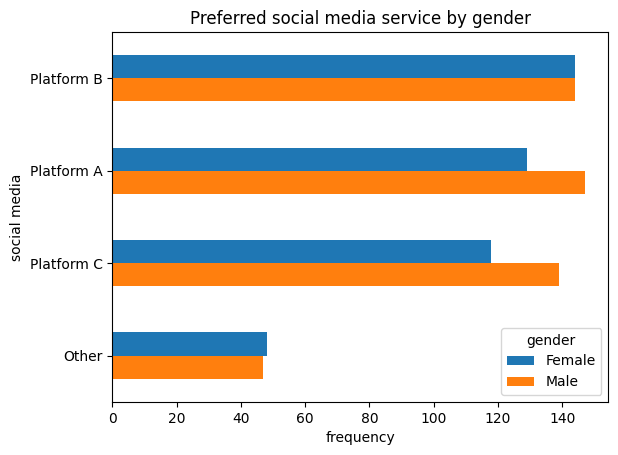

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

# Remove all 'Undisclosed' responses
df = df.loc[df['gender'] != 'Undisclosed']
# Generate cross tabulation
table = pd.crosstab(df['pref_service'], df['gender'], margins=True)
# Remove the All row, we don't need it
table.drop('All', axis='rows', inplace=True)
# Sort by the All column
table = table.sort_values(by='All', ascending=False)
# Remove the All column before plotting
table.drop('All', axis='columns', inplace=True)

ax = table.plot.barh()
ax.invert_yaxis()
ax.set_title('Preferred social media service by gender')
ax.set_xlabel('frequency')
ax.set_ylabel('social media')
plt.show()

#### Stacked Bar Chart

In [6]:
### Insert code for generating Stacked Bar Chart
### Note: Very minor changes from code for Group Bar Chart


#### Normalised Stack Bar Chart

In [7]:
### Insert code for generating Normalised Stacked Bar Chart (i.e., each bar sums to 100%)
### Note: Some changes from code for Stacked Bar Chart


#### Heat Map

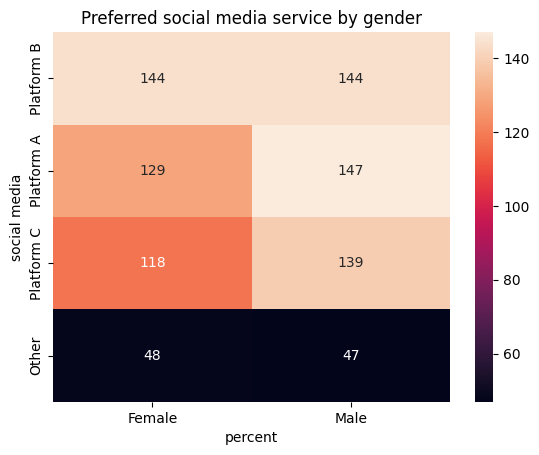

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Remove all 'Undisclosed' responses
df = df.loc[df['gender'] != 'Undisclosed']
# Generate cross tabulation
table = pd.crosstab(df['pref_service'], df['gender'])
# Sort by female responses
table = table.sort_values(by='Female', ascending=False)

ax = sns.heatmap(table, annot=True, fmt='d')
# ax = sns.heatmap(table, annot=True, fmt='d', cmap='coolwarm', cbar=False)
ax.set_title('Preferred social media service by gender')
ax.set_xlabel('percent')
ax.set_ylabel('social media')
plt.show()

### 4.2.2 Ordinal Variables

Suppose we wish to do a quick survey...

How do the following factors influence you in donating to charity?
- personal values
- own sense of morality/ethics
- particular belief I have in specific cause
- faith
- personal experience

In [9]:
# Let's generate sample responses

import numpy as np
import pandas as pd
import os

np.random.seed(100)

# Define the possible rating levels
rating_levels = ['not at all', 'a little', 'neutral', 'strongly', 'very strongly']

# Define the factors
factors = ['values', 'experience', 'faith', 'cause']

# Generate sample data for n respondents
n = 200
sample_data = []

for i in range(n):
    individual_data = {
        'values': np.random.choice(rating_levels),
        'experience': np.random.choice(rating_levels),
        'faith': np.random.choice(rating_levels),
        'cause': np.random.choice(rating_levels)
    }
    sample_data.append(individual_data)

# Create a DataFrame to organize the data
df = pd.DataFrame(sample_data)
print(df.head())

# Optionally, save the data to a CSV file
if not os.path.exists("generosity.csv"):
    df.to_csv("generosity.csv", index=False)
    print("File saved.")
else:
    print("File exists. Not saved.")


       values     experience     faith          cause
0  not at all     not at all  strongly     not at all
1     neutral  very strongly   neutral        neutral
2     neutral        neutral  a little     not at all
3  not at all  very strongly  strongly  very strongly
4     neutral     not at all  strongly       a little
File saved.


#### Normalised Stacked Bar

In [10]:
# Load the data file (if saved to CSV file)
# Each factor is represented by a separate column
df = pd.read_csv('generosity.csv')
print(df.head())
print(df.info())

       values     experience     faith          cause
0  not at all     not at all  strongly     not at all
1     neutral  very strongly   neutral        neutral
2     neutral        neutral  a little     not at all
3  not at all  very strongly  strongly  very strongly
4     neutral     not at all  strongly       a little
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   values      200 non-null    object
 1   experience  200 non-null    object
 2   faith       200 non-null    object
 3   cause       200 non-null    object
dtypes: object(4)
memory usage: 6.4+ KB
None


In [11]:
# Melt all columns into a single variable
df = df.melt(var_name='motivation', value_name='rating')
# Convert to long format using pd.melt()
df['motivation'] = df['motivation'].astype('category')
rating_levels = ['not at all', 'a little', 'neutral', 'strongly', 'very strongly']
df['rating'] = df['rating'].astype(
    pd.CategoricalDtype(categories=rating_levels, ordered=True))

print(df.head())
print(df.info())

  motivation      rating
0     values  not at all
1     values     neutral
2     values     neutral
3     values  not at all
4     values     neutral
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   motivation  800 non-null    category
 1   rating      800 non-null    category
dtypes: category(2)
memory usage: 2.1 KB
None


In [12]:
# Create a normalised table (sum to 100% across rows)
table = pd.crosstab(df['motivation'], df['rating'], normalize='index') * 100

# Sort by highest value
table.sort_values(by='very strongly', inplace=True)
table.round(2)

rating,not at all,a little,neutral,strongly,very strongly
motivation,,,,,
cause,21.0,20.0,19.5,23.0,16.5
values,17.5,19.5,22.0,20.0,21.0
faith,16.0,20.0,17.5,25.0,21.5
experience,17.0,18.5,23.5,17.5,23.5


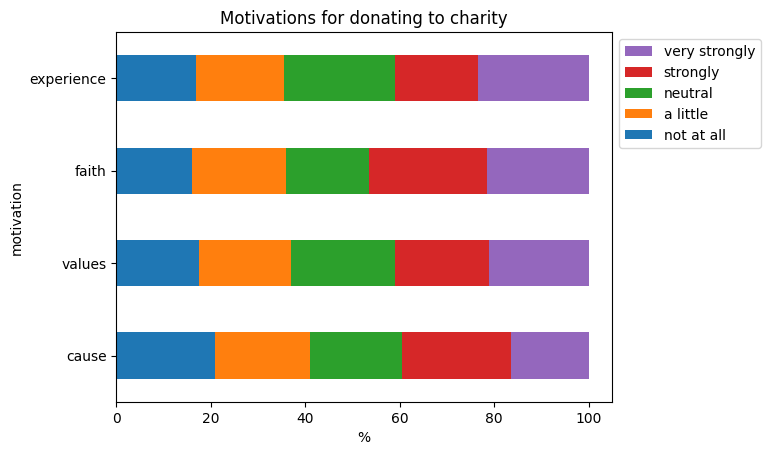

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

ax = table.plot.barh(stacked=True)

# Manually draw legend: reverse order of labels and plot outside axes
handles, labels = ax.get_legend_handles_labels()
ax.legend(list(reversed(handles)), 
          list(reversed(labels)), 
          bbox_to_anchor=(1.0, 1.0))

ax.set_xlabel('%')
ax.set_title('Motivations for donating to charity')

plt.show()

#### Heat Map

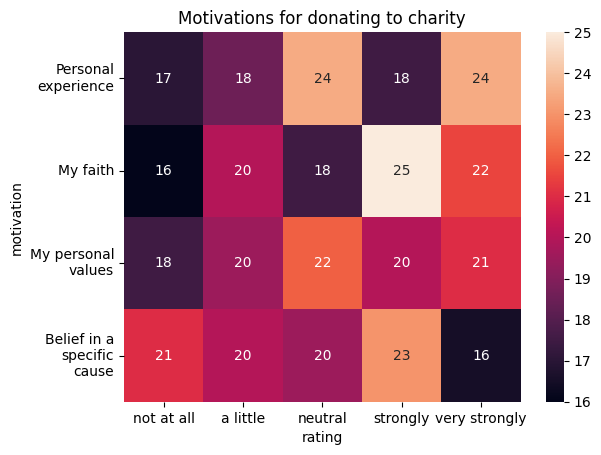

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from textwrap import wrap

ax = sns.heatmap(table, annot=True)
ax.set_title('Motivations for donating to charity')

# Better y=axis labels
motivations = {'experience': 'Personal experience',
               'faith': 'My faith',
               'cause': 'Belief in a specific cause',
               'values': 'My personal values'}

# Use textwrap library to break long lines automatically
motivations = {k: '\n'.join(wrap(v, 12)) for k, v in motivations.items()}
# Replace original y-axis labels
ax.set_yticklabels(table.index.map(motivations), rotation=0)
# Invert y-axis so most highly rated is at the top
ax.invert_yaxis()
plt.show()

#### Diverging Stacked Bar Chart (Likert Plot)

In [15]:
df = pd.read_csv('generosity.csv')
df.head()

,values,experience,faith,cause
0,not at all,not at all,strongly,not at all
1,neutral,very strongly,neutral,neutral
2,neutral,neutral,a little,not at all
3,not at all,very strongly,strongly,very strongly
4,neutral,not at all,strongly,a little


In [16]:
# Install plot_likert (if needed)
# !pip install plot_likert

In [17]:
# Coursera videos uses the 'likert_plot' library which could not be found. 
# This demo uses the 'plot_likert' library instead, with a 5-point Likert scale

import plot_likert
import matplotlib.pyplot as plt
import warnings

# Suppress only FutureWarnings
warnings.filterwarnings('ignore', category=FutureWarning)

rating_levels = ['not at all', 'a little', 'neutral', 'strongly', 'very strongly']
ax = plot_likert.plot_likert(df, rating_levels, plot_percentage=True,
                            colors=plot_likert.colors.likert5,
                            bar_labels=True)

ax.set_title('Motivations for donating to charity')
plt.show()

# Reference -- https://www.kaggle.com/code/robi5bd/plot-likert-scale-by-python

ModuleNotFoundError: No module named 'plot_likert'

### 4.2.3 Numerical and Categorical Data

#### Cat Plot: One Categorical, One Numerical Variable

In [ ]:
# Load the data on preferred social media platforms (previously generated)
df = pd.read_csv('social_media.csv', index_col=0)
df['pref_service'] = df['pref_service'].astype('category')
print(df.head())
print(df.info())

In [ ]:
# Calculate the median age for each 'pref_service' group
median_age = df.groupby('pref_service')[['age']].median()\
    .sort_values(by='age', ascending=False)

# Strip plot (default)
g = sns.catplot(x='age', y='pref_service', data=df, 
                order=median_age.index, hue='pref_service', 
                palette='colorblind')

g.ax.set_title('Social media preferences by age')
g.ax.set_ylabel('platform')
g.ax.set_xlabel('age')
plt.show()

#### Box Plot: One Categorical, One Numerical Variable

In [ ]:
# Load the data on preferred social media platforms (previously generated)
df = pd.read_csv('social_media.csv', 
                 index_col=0,
                 usecols=['id', 'age', 'pref_service'])

# Calculate the median age of each favourite genre
median_age = df.groupby('pref_service').median().sort_values(
    by='age', ascending=False)

# Create a new data type where genres are ordered by median age
ordered_platform_dtype = pd.CategoricalDtype(median_age.index, ordered=True)

# Assign new ordered categorical dtype
df['pref_service'] = df['pref_service'].astype(ordered_platform_dtype)

# Create the boxplot
ax = df.boxplot(by='pref_service')
ax.set_title('Social media preferences by age')
ax.figure.suptitle('')
ax.set_xlabel('platform')
ax.set_ylabel('age')
plt.show()

In [ ]:
# Load the data on preferred social media platforms (previously generated)
df = pd.read_csv('social_media.csv', 
                 index_col=0,
                 usecols=['id', 'age', 'pref_service'])

# Set correct data types
df['pref_service'] = df['pref_service'].astype('category')

# Calculate the median age of each favourite genre
median_age = df.groupby('pref_service').median().sort_values(
    by='age', ascending=False)

# Box plot
g = sns.catplot(x='age', y='pref_service', kind='box', data=df, 
                order=median_age.index, hue='pref_service',
                palette='colorblind')
g.ax.set_title('Social media preferences by age')
g.ax.set_ylabel('platform')
g.ax.set_xlabel('age')
plt.show()

#### Cat Plot: Two Categorical Variables, One Numerical

In [ ]:
# Load the data on preferred social media platforms (previously generated)
df = pd.read_csv('social_media.csv', 
                 index_col=0,
                 usecols=['id', 'age', 'gender', 'pref_service'])

# Remove all 'Undisclosed' gender responses
df = df.loc[df['gender'] != 'Undisclosed']

# Set correct data types
df['gender'] = df['gender'].astype('category')
df['pref_service'] = df['pref_service'].astype('category')

# Calculate the median age of each favourite genre
median_age = df.groupby('pref_service')[['age']].median().sort_values(
    by='age', ascending=False)

# Swarm plot
g = sns.catplot(x='age', y='pref_service', hue='gender',
                kind='swarm', data=df, order=median_age.index, 
                palette='colorblind')
g.ax.set_title('Social media preferences by age and gender')
g.ax.set_ylabel('platform')
g.ax.set_xlabel('age')
plt.show()

#### Box Plot: Two Categorical Variables, One Numeric

In [ ]:
df = pd.read_csv('social_media.csv', 
                 index_col=0,
                 usecols=['id', 'age', 'gender', 'pref_service'])

# Remove all 'Undisclosed' gender responses
df = df.loc[~df['gender'].isin(['Undisclosed'])]

# Set correct data types
df['gender'] = df['gender'].astype('category')
df['pref_service'] = df['pref_service'].astype('category')

# Calculate the median age of each favourite genre
median_age = df.groupby('pref_service')[['age']].median().sort_values(
    by='age', ascending=False)

# Box plot
g = sns.catplot(x='age', y='pref_service', 
                hue='gender', kind='box', data=df, order=median_age.index, 
                palette='colorblind')
g.ax.set_title('Social media preferences by age and gender')
g.ax.set_ylabel('social media')
g.ax.set_xlabel('age')
plt.show()

### 4.2.4 Processing Numerical Data

#### Correlation

**Correlation is not causation!**

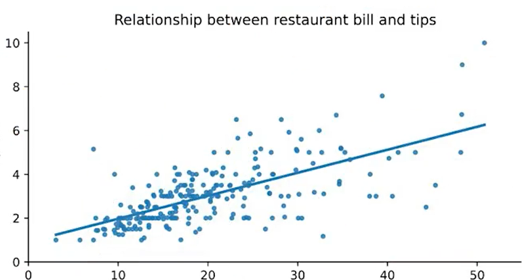


#### Correlation Coefficient
- a measure of how two variables change in a similar way
- a relationship is generally assumed to be linear
- quantified on a scale -1 < *r* <1

#### Sample Pearson Correlation Coefficient
- r = 1: x and y are positively correlated
- r = 0: x and y and not correlated
- r = -1: x and y are negatively correlated

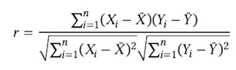

#### Visualising Correlation


In [ ]:
# First, let's generate some data
np.random.seed(1)           
n = 30
mean = 10
sd = 4
x = np.random.normal(mean, sd, n)
noise = np.random.normal(0, 4, n)
df = pd.DataFrame({'x': x,
                   'perfect_pos': x,
                   'perfect_neg': np.max(x) - x,
                   'none': np.random.normal(mean, sd, n),
                   'positive': x + noise,
                   'negative': np.max(x) - x + noise})
df.round(1).head()

In [ ]:
# Next, manually visualise each relation as subplots on the same figure
from scipy import stats

# Create a figure object and an array of axes objects
# The shape of the axes array is (2, 3): 2 rows, 3 columns
fig, axes = plt.subplots(2, 3, figsize=(8,4))

# Convert axes to 1D array
axes = axes.ravel()

# Loop over columns and draw on separate axes
for var, i in zip(df.columns[1:], range(0, 6)):
    df.plot.scatter('x', var, ax=axes[i])
    # Compute regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, df[var])
    axes[i].plot(x, slope * x + intercept, 'r')
    axes[i].set_title('r = {:0.2f}'.format(r_value))

# Delete unused (last) axes
fig.delaxes(axes[-1])

# Increase the space between subplots
fig.subplots_adjust(wspace=0.45, hspace=0.65)

plt.show()

In [ ]:
# Seaborn scatterplots

# Create a figure object and an array of axes objects
# The shape of the axes array is (2, 3):: 2 rows, 3 columns
fig, axes = plt.subplots(2, 3, figsize=(8, 4))

sns.regplot(x='x', y='perfect_pos', data=df, ax=axes[0, 0])
sns.regplot(x='x', y='perfect_neg', data=df, ax=axes[0, 1])
sns.regplot(x='x', y='none', data=df, ax=axes[0, 2])
sns.regplot(x='x', y='positive', data=df, ax=axes[1, 0])
sns.regplot(x='x', y='negative', data=df, ax=axes[1, 1])

# Delete unused (last) axes
fig.delaxes(axes[1, 2])

# Increase the space between subplots
fig.subplots_adjust(wspace=0.45, hspace=0.65)

plt.show()

Regression estimate confidence bands
- conventional confidence interval is 95%
- confidence bands are 95% sure to contain the best-fit regression line

In [ ]:
# Scatterplot matrix using pandas
axes = pd.plotting.scatter_matrix(df, alpha=0.5, diagonal='kde',
                                  figsize=(9, 6.5), range_padding=0.22)
plt.show()

In [ ]:
# Scatterplot matrix using seaborn
sns.pairplot(df, kind='reg')
plt.show()

#### Anscombe's Quartet

**Visualising data is very important!**

- Same statistical properties
    * mean, variance for both x and y
    * same correlation between x and y
    * same linear regression line

 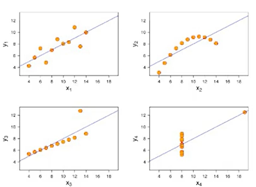
